# EAD back-testing by utilisation band and the LGD and EAD validation battery

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 03 and 05 of this topic (the LGD ladder and the CCF estimators)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- back-test an EAD model in currency by utilisation band with `ead_backtest_by_band`, compute the band gaps by hand, and read its metric, statistic and light;
- reproduce the committed back-test of the eight C09 EAD models from the band totals the artifact stores, and see which model fails in which band;
- run the three LGD tests of the engine, `lgd_calibration_by_segment`, `lgd_calibration_over_time` and `lgd_discrimination`, compute their statistics by hand on a small example and read their lights;
- read the committed LGD battery of C08 for the 2014-19 cohort, verify its Bonferroni adjustment from the rows it stores, and say why calibration and discrimination can disagree.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation import lgd_ead as tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

Three committed artifacts. `data/derived/C09/level-3.json` is the revolving-lines generator of case C09 at acceleration level 3 (a known truth: synthetic lines, not any lender's), with the back-test of eight EAD models by utilisation band in `outputs.ead_backtest`. `data/derived/C08/dc-2014-19.json` is the C08 variant for the defaults of 2014 to 2019 (a charge-off proxy on the SBA 7(a) small-business loans, notebook 01), with the LGD tests of the six ladder rungs in `tests`. The third, `data/derived/C08/dc-2020-23.json`, is read only for its number of loans in step 6. They were baked by an older engine than the installed one, and the next cell prints the versions.

The engine's LGD and EAD tests are plain functions whose lights are **Contraste internal gates, not regulatory thresholds** (their docstrings say so): each states its rule, and the pipeline records the parameters with the result.

In [2]:
# Open the two artifacts and print the versions that baked them, the bands and the models of the back-test
ROOT = Path("../../..").resolve()
c09 = json.loads((ROOT / "data" / "derived" / "C09" / "level-3.json").read_text(encoding="utf-8"))
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2014-19.json").read_text(encoding="utf-8"))
backtest = c09["outputs"]["ead_backtest"]
print("C09:", c09["provenance"]["riskvalidation_version"], "| C08:", c08["provenance"]["riskvalidation_version"], "| installed:", rv.__version__)
print("bands of utilisation:", backtest["bands"], "|", backtest["currency"])
print("models back-tested:", sorted({r["model_id"] for r in backtest["rows"]}))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

C09: 0.6.0 | C08: 0.6.0 | installed: 0.9.0
bands of utilisation: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 4.0] | USD
models back-tested: ['ccf-cohort-floor-cap', 'ccf-fixed-horizon-bounded-scale', 'ccf-fixed-horizon-censor', 'ccf-fixed-horizon-floor-cap', 'ccf-fixed-horizon-none', 'ccf-variable-horizon-floor-cap', 'direct-ead', 'utilisation-change']


## Method

### Step 1: the EAD back-test by band, by hand

An EAD model is judged in currency, not only as a factor (the research follows Tong et al. 2016 and Qi 2009 in this). The engine groups the facilities by utilisation band $[u_b, u_{b+1})$ (the last band is closed) and, for each band $b$ with predicted EADs $\hat{E}_i$ and realised EADs $E_i$:

$$\text{gap}_b = \sum_{i \in b}\hat{E}_i - \sum_{i \in b}E_i, \qquad \text{relative gap}_b = \frac{\text{gap}_b}{\sum_{i \in b}E_i}, \qquad \text{metric} = \max_b |\text{relative gap}_b|$$

The statistic is the relative gap of the total. The light is a Contraste internal gate: green when the metric is at most 0.10, amber up to 0.25, red above (`gap_amber` and `gap_red`, recorded with the result; the p-value is null). A band with no facility, or with a realised EAD of zero, does not enter the metric. (All from the docstring of `ead_backtest_by_band`.)

The cell invents six facilities in three bands, computes each band by hand and runs the engine on the same arrays.

In [3]:
# Six invented facilities in three utilisation bands: the band gaps by hand and then the engine's ead_backtest_by_band
utilisation = np.array([0.10, 0.15, 0.30, 0.35, 0.60, 0.90])
predicted = np.array([1_000.0, 1_200.0, 2_000.0, 2_200.0, 4_000.0, 5_000.0])
realised = np.array([1_100.0, 1_150.0, 2_500.0, 2_400.0, 3_600.0, 4_700.0])
edges = np.array([0.0, 0.2, 0.4, 1.0])
relative = []
for b in range(3):
    inside = (utilisation >= edges[b]) & ((utilisation < edges[b + 1]) | (b == 2))
    gap = predicted[inside].sum() - realised[inside].sum()
    relative.append(gap / realised[inside].sum())
    print(f"band [{edges[b]}, {edges[b + 1]}): n={inside.sum()} predicted {predicted[inside].sum():8.1f} realised {realised[inside].sum():8.1f} gap {gap:8.1f} relative gap {gap / realised[inside].sum():8.4f}")
print(f"metric by hand (max absolute relative gap): {max(abs(r) for r in relative):.4f} | relative gap of the total: {(predicted.sum() - realised.sum()) / realised.sum():.4f}")
res = tests.ead_backtest_by_band(predicted, realised, utilisation, edges, model_id="invented")
print(f"engine: metric {res.metric:.4f} | statistic {res.statistic:.4f} | light: {LIGHT[res.light.value]} | {res.policy_version}")

band [0.0, 0.2): n=2 predicted   2200.0 realised   2250.0 gap    -50.0 relative gap  -0.0222
band [0.2, 0.4): n=2 predicted   4200.0 realised   4900.0 gap   -700.0 relative gap  -0.1429
band [0.4, 1.0): n=2 predicted   9000.0 realised   8300.0 gap    700.0 relative gap   0.0843
metric by hand (max absolute relative gap): 0.1429 | relative gap of the total: -0.0032
engine: metric 0.1429 | statistic -0.0032 | light: amber | contraste-lgd-ead-battery-1.0.0; gap_amber=0.1; gap_red=0.25


### Step 2: the committed back-test, reproduced from its band totals

The C09 artifact does not keep the 50,000 lines of each replication, but it keeps what the back-test is made of: for each model and band, the number of defaulters, the predicted and the realised EAD in USD, the gap and the relative gap. The engine's metric depends only on those band totals, so the function can be run on them: one pseudo-facility per band, placed at the middle of the band, carrying the band's predicted and realised totals. The result must equal the committed metric, statistic and light. The next cell does this for the eight models and prints the match, with the version that baked the committed rows beside the installed one (they differ, so the match is a real check).

In [4]:
# Run ead_backtest_by_band on the band totals of each committed model and compare with the committed metric, statistic and light
committed = {t["model_id"]: t for t in c09["tests"] if t["test_id"] == "lgd_ead.ead_backtest_by_band"}
bands = np.array(backtest["bands"])
print("committed rows baked by", c09["provenance"]["riskvalidation_version"], "| recomputed with", rv.__version__)
print(f"{'model':34s} {'metric':>9s} {'committed':>11s} {'light':>8s} {'committed':>11s} {'worst band':>14s} {'match':>9s}")
all_match = True
for model_id, row in committed.items():
    rows = [r for r in backtest["rows"] if r["model_id"] == model_id]
    mid = np.array([(r["utilisation_lower"] + r["utilisation_upper"]) / 2 for r in rows])
    out = tests.ead_backtest_by_band(np.array([r["predicted_ead"] for r in rows]), np.array([r["realised_ead"] for r in rows]), mid, bands, model_id=model_id)
    worst = max(rows, key=lambda r: abs(r["relative_gap"]))
    match = bool(np.isclose(out.metric, row["metric"], atol=1e-8)) and out.light.value == row["light"] and bool(np.isclose(out.statistic, row["statistic"], atol=1e-8))
    all_match &= match
    print(f"{model_id:34s} {out.metric:9.4f} {row['metric']:11.4f} {LIGHT[out.light.value]:>8s} {LIGHT[row['light']]:>11s} {worst['band_id']:>6s} ({worst['relative_gap']:+.3f}) {match!s:>9s}")
print("all eight reproduced:", all_match)

committed rows baked by 0.6.0 | recomputed with 0.9.0
model                                 metric   committed    light   committed     worst band     match
ccf-fixed-horizon-none                0.0230      0.0230    green       green     u1 (+0.023)      True
ccf-fixed-horizon-censor              0.0476      0.0476    green       green     u1 (-0.048)      True
ccf-fixed-horizon-floor-cap           0.0190      0.0190    green       green     u3 (-0.019)      True
ccf-fixed-horizon-bounded-scale       0.0156      0.0156    green       green     u7 (-0.016)      True
ccf-cohort-floor-cap                  0.2033      0.2033    amber       amber     u1 (+0.203)      True
ccf-variable-horizon-floor-cap        0.0305      0.0305    green       green     u2 (+0.031)      True
direct-ead                            0.5719      0.5719      red         red     u7 (-0.572)      True
utilisation-change                    0.2195      0.2195    amber       amber     u5 (+0.219)      True
all eight r

### Step 3: where the models fail

A single metric hides where. The figure draws the relative gap by band for three of the models: the fixed-horizon CCF model with floor and cap, the direct EAD model and the utilisation-change model. The bands are in utilisation (the drawn share of the limit) at the reference date, so the right-hand bands hold lines that were already fully drawn or over their limit.

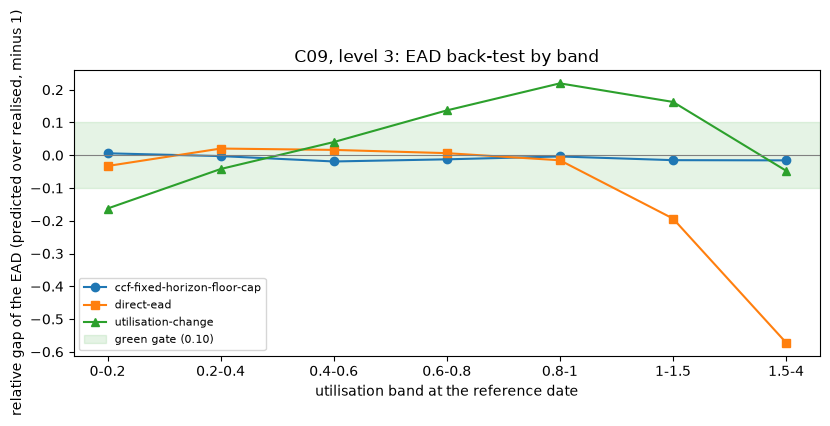

In [5]:
# Draw the relative gap by utilisation band for three of the eight EAD models
fig, ax = plt.subplots(figsize=(8.4, 3.8))
labels = [f"{lo:g}-{hi:g}" for lo, hi in zip(bands[:-1], bands[1:])]
for model_id, marker in (("ccf-fixed-horizon-floor-cap", "o"), ("direct-ead", "s"), ("utilisation-change", "^")):
    rows = [r for r in backtest["rows"] if r["model_id"] == model_id]
    ax.plot(range(len(rows)), [r["relative_gap"] for r in rows], marker=marker, label=model_id)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.axhspan(-0.10, 0.10, color="tab:green", alpha=0.12, label="green gate (0.10)")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_xlabel("utilisation band at the reference date")
ax.set_ylabel("relative gap of the EAD (predicted over realised, minus 1)")
ax.set_title("C09, level 3: EAD back-test by band")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Step 4: the three LGD tests on a small example, by hand

The engine's LGD tests take the realised and the predicted LGD of each loan. The cell invents twelve loans (realised and predicted values written out) so that every intermediate is visible, and computes by hand what the first and third test compute:

- `lgd_calibration_by_segment`: a paired t-test of the gap $d_i = \text{realised}_i - \text{predicted}_i$, $t = \bar d / (s_d / \sqrt{N})$ with $N - 1$ degrees of freedom and a two-sided p-value; the metric is $\bar d$; the light is green when the p-value is at least 0.05, amber from 0.01 and red below.
- `lgd_discrimination`: the Spearman rank correlation $\rho$ of predicted and realised LGD, which is the Pearson correlation of the ranks (ties by average rank); the light is green when $\rho \ge 0.30$, amber from 0.10, red below, a Contraste gate, because LGD rank power is modest in the literature.

(The rules and gates are those of the docstrings of the two functions.) The p-value of the t statistic comes from the engine, which uses the t distribution; the notebook computes the statistic itself.

In [6]:
# Twelve invented loans: the paired t statistic and the Spearman correlation by hand, then the engine's two tests
real = np.array([0.55, 0.70, 0.40, 0.90, 0.62, 0.35, 0.80, 0.58, 0.66, 0.48, 0.75, 0.52])
pred = np.array([0.50, 0.60, 0.45, 0.70, 0.61, 0.40, 0.65, 0.55, 0.52, 0.51, 0.62, 0.47])
d = real - pred
n = d.size
mean_d, sd_d = d.mean(), d.std(ddof=1)
se = sd_d / np.sqrt(n)
print(f"N={n} | mean gap {mean_d:.4f} | standard deviation of the gaps {sd_d:.4f} | standard error {se:.4f} | t = {mean_d / se:.4f}")
rank = lambda x: np.argsort(np.argsort(x)) + 1.0
rho = np.corrcoef(rank(real), rank(pred))[0, 1]
print(f"ranks of the realised values: {rank(real).astype(int).tolist()}")
print(f"ranks of the predicted values: {rank(pred).astype(int).tolist()} | Spearman by hand = {rho:.4f}")

by_segment = tests.lgd_calibration_by_segment(real, pred, segment="invented")
rank_test = tests.lgd_discrimination(real, pred, segment="invented")
print(f"lgd_calibration_by_segment: t={by_segment.statistic:.4f} p={by_segment.p_value:.4f} metric={by_segment.metric:.4f} 95% interval of the mean gap=({by_segment.extras['ci_low']:.4f}, {by_segment.extras['ci_high']:.4f}) light: {LIGHT[by_segment.light.value]}")
print(f"lgd_discrimination:         rho={rank_test.statistic:.4f} p={rank_test.p_value:.4g} light: {LIGHT[rank_test.light.value]}")

N=12 | mean gap 0.0608 | standard deviation of the gaps 0.0834 | standard error 0.0241 | t = 2.5271
ranks of the realised values: [5, 9, 2, 12, 7, 1, 11, 6, 8, 3, 10, 4]
ranks of the predicted values: [4, 8, 2, 12, 9, 1, 11, 7, 6, 5, 10, 3] | Spearman by hand = 0.9441
lgd_calibration_by_segment: t=2.5271 p=0.0281 metric=0.0608 95% interval of the mean gap=(0.0079, 0.1138) light: amber
lgd_discrimination:         rho=0.9441 p=3.927e-06 light: green


### Step 5: the same loans over time

`lgd_calibration_over_time(realised, predicted, period)` runs the paired t-test inside each period (a default year or a cohort index), keeps the periods with at least two observations and a nonzero spread, and combines them:

$$\text{statistic} = \max_k |t_k|, \qquad p = \min\big(1,\; K\,\min_k p_k\big), \qquad \text{metric} = \max_k |\bar d_k|$$

with $K$ the number of periods tested (a Bonferroni adjustment, so that looking at several periods does not inflate the chance of a false alarm). A period with zero spread and a gap other than zero makes the light red. The cell assigns the twelve loans to three years of four, runs the test and checks the adjustment from the period rows the engine returns.

In [7]:
# Run lgd_calibration_over_time on the twelve loans in three years and check the Bonferroni adjustment from its period rows
period = np.repeat([2019, 2020, 2021], 4)
over_time = tests.lgd_calibration_over_time(real, pred, period, model_id="invented")
for row in over_time.extras["periods"]:
    print(f"period {row['period']}: n={row['n']} mean gap {row['mean_gap']:.4f} t={row['t']:.4f} p={row['p']:.4f}")
k = over_time.extras["n_periods_tested"]
print(f"K={k} | statistic (largest |t|) {over_time.statistic:.4f} | p = min(1, K * min p) = {min(1.0, k * min(r['p'] for r in over_time.extras['periods'])):.4f} | engine p {over_time.p_value:.4f} | light: {LIGHT[over_time.light.value]}")

period 2019: n=4 mean gap 0.0750 t=1.4412 p=0.2452
period 2020: n=4 mean gap 0.0350 t=0.8347 p=0.4651
period 2021: n=4 mean gap 0.0725 t=1.8280 p=0.1650
K=3 | statistic (largest |t|) 1.8280 | p = min(1, K * min p) = 0.4950 | engine p 0.4950 | light: green


### Step 6: the committed LGD battery of C08, 2014-19

The C08 variant keeps the engine's test rows for each ladder rung: calibration by segment (the whole cohort is the segment), discrimination, and calibration over time. The over-time test of a cutoff variant runs over every default after the training cutoff, so its periods are the default years and its number of loans is larger than the cohort's; the cell checks that figure. It then prints, for the six rungs, the mean gap with its p-value and light, the Spearman correlation with its light and the over-time statistic, and verifies the Bonferroni adjustment from the stored period rows of the fractional-logit rung.

In [8]:
# Print the committed battery of the six rungs for the 2014-19 cohort and verify the Bonferroni adjustment from the stored period rows
rows = {(t["model_id"], t["test_id"].split(".")[1]): t for t in c08["tests"] if t["model_id"]}
n_cohort = c08["outputs"]["lgd_distribution"]["n"]
over = rows[("L2-fractional-logit", "lgd_calibration_over_time")]
c08_2020 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2020-23.json").read_text(encoding="utf-8"))["outputs"]["lgd_distribution"]["n"]
print(f"loans in the cohort 2014-19: {n_cohort:,} | in the cohort 2020-23: {c08_2020:,} | loans in the over-time test: {over['n']:,} | sum of the two cohorts: {n_cohort + c08_2020:,}")
print("baked by riskvalidation:", c08["provenance"]["riskvalidation_version"])
print(f"{'rung':22s} {'mean gap':>12s} {'p':>10s} {'light':>8s} | {'Spearman':>8s} {'light':>8s} | {'max |t| by year':>18s} {'light':>8s}")
for rung in sorted({k[0] for k in rows}):
    a, b, c = (rows[(rung, name)] for name in ("lgd_calibration_by_segment", "lgd_discrimination", "lgd_calibration_over_time"))
    print(f"{rung:22s} {a['metric']:12.4f} {a['p_value']:10.2e} {LIGHT[a['light']]:>8s} | {b['metric']:8.4f} {LIGHT[b['light']]:>8s} | {c['statistic']:18.3f} {LIGHT[c['light']]:>8s}")
periods = over["extras"]["periods"]
k_tested = len(periods)
print()
print(f"fractional logit: periods tested K={k_tested} | min p = {min(r['p'] for r in periods):.3e} | K * min p = {k_tested * min(r['p'] for r in periods):.3e} | committed p = {over['p_value']:.3e}")

loans in the cohort 2014-19: 36,481 | in the cohort 2020-23: 13,930 | loans in the over-time test: 50,411 | sum of the two cohorts: 50,411
baked by riskvalidation: 0.6.0
rung                       mean gap          p    light | Spearman    light |    max |t| by year    light
L1-ols                       0.0058   8.46e-05      red |   0.4390    green |              7.066      red
L2-fractional-logit          0.0164   4.37e-28      red |   0.4399    green |             10.799      red
L3-beta                      0.0138   2.88e-20      red |   0.4257    green |              9.555      red
L4-hurdle                    0.0165   1.45e-28      red |   0.4405    green |             10.845      red
L5-gradient-boosted          0.0300   1.85e-96      red |   0.5139    green |             17.831      red
L6-tobit                     0.0167   1.88e-29      red |   0.4376    green |              9.229      red

fractional logit: periods tested K=10 | min p = 4.991e-27 | K * min p = 4.991e-26 | com

The mean gap is positive for every rung and the calibration light is red for every rung, while the Spearman correlation is above the green gate for all of them: the models order the loans acceptably and place their level too low. The last figure shows the gap by default year for the fractional-logit rung, which is where the over-time test finds its largest t.

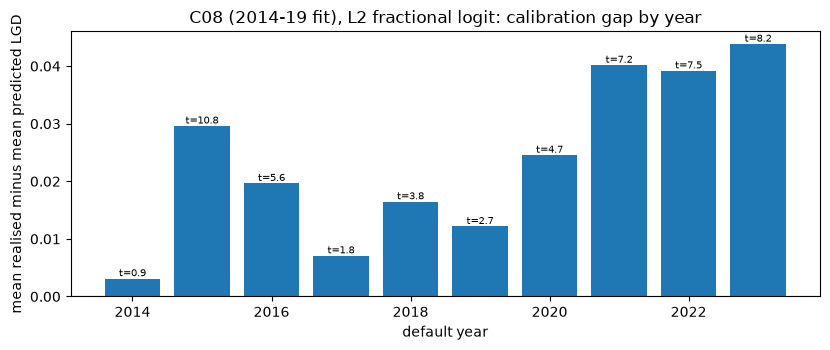

In [9]:
# Draw the mean gap by default year of the fractional-logit rung, with the t statistic of each year in the labels
fig, ax = plt.subplots(figsize=(8.4, 3.6))
years = [r["period"] for r in periods]
ax.bar(years, [r["mean_gap"] for r in periods], color="tab:blue")
for r in periods:
    ax.annotate(f"t={r['t']:.1f}", (r["period"], r["mean_gap"]), ha="center", va="bottom", fontsize=7)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("default year")
ax.set_ylabel("mean realised minus mean predicted LGD")
ax.set_title("C08 (2014-19 fit), L2 fractional logit: calibration gap by year")
fig.tight_layout()
plt.show()

## Results

- **The back-test is a worked formula.** On the six invented facilities the band gaps are -0.0222, -0.1429 and 0.0843, so the metric is 0.1429 (amber) and the relative gap of the total is only -0.0032: a total can look right while a band is wrong. The engine returns the same numbers.
- **The committed back-test is reproduced exactly.** The engine, run on the band totals the artifact stores, gives the committed metric, statistic and light for all eight C09 models at level 3, although the committed rows were baked by engine 0.6.0 and this notebook runs 0.8.1.
- **The models fail in different places.** The fixed-horizon factor models are green (metrics 0.0156 to 0.0476) and the variable-horizon one too (0.0305). The cohort design is amber at 0.2033, worst in the lowest band (+0.203). The utilisation-change model is amber at 0.2195, worst in the band from 0.8 to 1.0. The direct EAD model is red at 0.5719, worst in the highest band, from 1.5 to 4.0 (-0.572), the lines over their limit that it cannot predict.
- **Every LGD test can be computed by hand.** On the twelve invented loans the mean gap is 0.0608 with a standard deviation of 0.0834 and a standard error of 0.0241, so t = 2.5271 and the engine's p-value is 0.0281 (amber); the Spearman correlation is 0.9441 by hand and by the engine (green).
- **The over-time test is a Bonferroni-adjusted maximum.** With three periods the largest |t| is 1.8280 and the adjusted p-value 0.4950, which is three times the smallest period p-value.
- **C08, 2014-19: calibration is red for every rung and discrimination is green for every rung.** The mean gaps run from 0.0058 to 0.0300 with p-values from 8.46e-05 to 1.85e-96, the Spearman correlations from 0.4257 to 0.5139, and the over-time statistics from 7.066 to 17.831. The light is set by the p-value, not by the size of the gap: with 36,481 loans a gap of 0.0058 is already red. The over-time test covers 50,411 loans, the sum of the 2014-19 and 2020-23 cohorts, and its adjustment checks out on the stored rows (K = 10, 10 times 4.991e-27 equals the committed 4.991e-26).

What the notebook does not do: it does not recompute the replications of C09 or the loan-level LGD rows of C08, which are not committed; where it recomputes a committed result it does so from the stored band totals. The invented loans and facilities show the arithmetic only.

## Summary

- An EAD model is back-tested in currency by utilisation band: the band gaps, their relative size, and the largest of them as the metric, with a green gate at 0.10 and a red one at 0.25 that are Contraste's own.
- The committed back-test of the eight C09 models is reproduced exactly by the engine from the band totals alone, which is a check of the artifact against the installed engine.
- The LGD tests are a paired t on the mean gap, a Spearman correlation against fixed gates, and a Bonferroni-adjusted paired t over time; each can be computed by hand on a small example.
- In C08 the calibration light is red for every rung while discrimination is green: calibration and ranking are different questions, and the battery asks both.

**What to try next.** Change the predicted EADs of step 1 so that one band moves from green to amber and then red; then continue with notebook 07, which sets the C08 and C09 results beside the benchmark evidence in the literature.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: the document behind the PD tests of topic 01; the LGD and EAD tests of this notebook follow the engine's own docstrings and gates. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Tong, E. N. C., Mues, C., Brown, I. and Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Loterman, G., Brown, I., Martens, D., Mues, C. and Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Spearman, C. (1904), The proof and measurement of association between two things, American Journal of Psychology 15(1). https://doi.org/10.2307/1412159
- The engine's own documentation of `ead_backtest_by_band`, `lgd_calibration_by_segment`, `lgd_calibration_over_time` and `lgd_discrimination` (release 0.8.1), which states every rule and gate quoted above.
- This repository: `docs/design/SDD.md` (cases C08 and C09), `data/derived/C09/level-3.json` and `data/derived/C08/dc-2014-19.json`.